<a href="https://colab.research.google.com/github/Shreevatsa-NP/BIS/blob/main/greywolf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration 1: Best Distance = 369.22
Iteration 2: Best Distance = 345.03
Iteration 3: Best Distance = 338.95
Iteration 4: Best Distance = 338.95
Iteration 5: Best Distance = 279.80
Iteration 6: Best Distance = 279.80
Iteration 7: Best Distance = 279.80
Iteration 8: Best Distance = 279.80
Iteration 9: Best Distance = 279.80
Iteration 10: Best Distance = 279.80
Iteration 11: Best Distance = 279.80
Iteration 12: Best Distance = 279.80
Iteration 13: Best Distance = 272.77
Iteration 14: Best Distance = 264.83
Iteration 15: Best Distance = 264.83
Iteration 16: Best Distance = 264.83
Iteration 17: Best Distance = 264.83
Iteration 18: Best Distance = 264.83
Iteration 19: Best Distance = 264.83
Iteration 20: Best Distance = 264.83
Iteration 21: Best Distance = 264.83
Iteration 22: Best Distance = 264.83
Iteration 23: Best Distance = 264.83
Iteration 24: Best Distance = 248.97
Iteration 25: Best Distance = 248.97
Iteration 26: Best Distance = 248.97
Iteration 27: Best Distance = 248.97
Iteration 

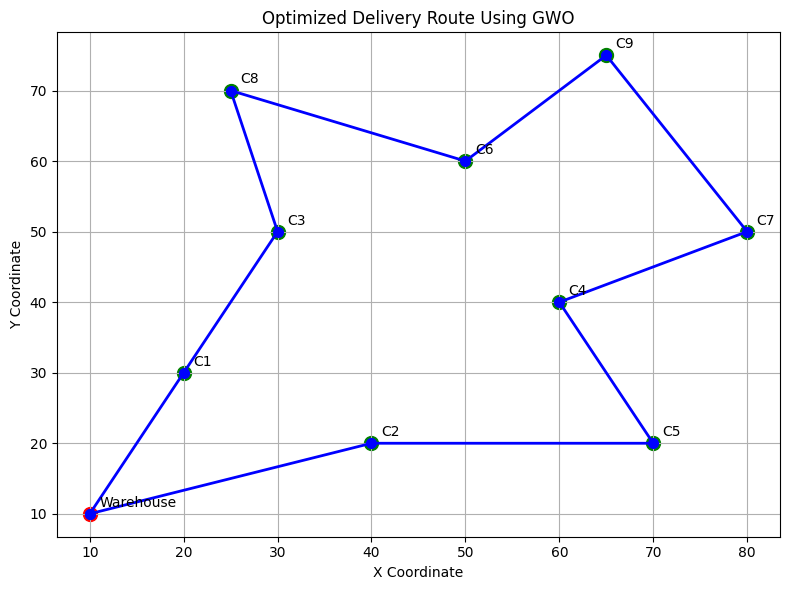

In [54]:

import numpy as np
import matplotlib.pyplot as plt

locations = np.array([
    [10, 10],
    [20, 30],
    [40, 20],
    [30, 50],
    [60, 40],
    [70, 20],
    [50, 60],
    [80, 50],
    [25, 70],
    [65, 75]
])

N = len(locations)
NUM_WOLVES = 30
MAX_ITER = 200

distance = np.zeros((N, N))

for i in range(N):
    for j in range(N):
        distance[i, j] = np.linalg.norm(
            locations[i] - locations[j]
        )

def fitness(route):
    total_distance = 0

    for i in range(len(route) - 1):
        total_distance += distance[
            route[i], route[i + 1]
        ]

    total_distance += distance[route[-1], route[0]]

    return total_distance

def initialize_wolves():
    wolves = []

    for _ in range(NUM_WOLVES):
        route = np.random.permutation(
            np.arange(1, N)
        )
        route = np.insert(route, 0, 0)
        wolves.append(route)

    return np.array(wolves)

wolves = initialize_wolves()

def update_route(wolf, alpha, beta, delta):
    new_route = wolf.copy()
    guides = [alpha, beta, delta]

    for guide in guides:
        i, j = np.random.choice(
            np.arange(1, N), 2, replace=False
        )

        if guide[i] != new_route[i]:
            target = np.where(
                new_route == guide[i]
            )[0][0]

            new_route[i], new_route[target] = (
                new_route[target],
                new_route[i]
            )

    if np.random.rand() < 0.2:
        i, j = np.random.choice(
            np.arange(1, N), 2, replace=False
        )

        new_route[i], new_route[j] = (
            new_route[j],
            new_route[i]
        )

    return new_route

best_route = None
best_fitness = float("inf")

for iteration in range(MAX_ITER):

    fitness_values = np.array([
        fitness(wolf) for wolf in wolves
    ])

    sorted_indices = np.argsort(fitness_values)

    alpha = wolves[sorted_indices[0]].copy()
    beta = wolves[sorted_indices[1]].copy()
    delta = wolves[sorted_indices[2]].copy()

    if fitness(alpha) < best_fitness:
        best_fitness = fitness(alpha)
        best_route = alpha.copy()

    new_wolves = []

    for wolf in wolves:
        updated = update_route(
            wolf, alpha, beta, delta
        )
        new_wolves.append(updated)

    wolves = np.array(new_wolves)

    print(
        f"Iteration {iteration + 1}: "
        f"Best Distance = {best_fitness:.2f}"
    )

print("\nOPTIMIZED DELIVERY ROUTE")

print("Warehouse", end="")

for customer in best_route[1:]:
    print(f" -> Customer {customer}", end="")

print(" -> Warehouse")

print(
    "\nMinimum Delivery Distance:",
    round(best_fitness, 2)
)

route_points = locations[best_route]

route_points = np.vstack([
    route_points,
    route_points[0]
])

plt.figure(figsize=(8, 6))

plt.plot(
    route_points[:, 0],
    route_points[:, 1],
    "b-o",
    linewidth=2,
    markersize=7
)

for i, point in enumerate(locations):

    if i == 0:
        label = "Warehouse"
        color = "red"
    else:
        label = f"C{i}"
        color = "green"

    plt.scatter(
        point[0], point[1],
        color=color,
        s=100
    )

    plt.text(
        point[0] + 1,
        point[1] + 1,
        label
    )

plt.title("Optimized Delivery Route Using GWO")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.grid(True)
plt.tight_layout()
plt.show()
